# Exploring VIIRS Vegetation Data From the Earthdata Cloud

**Authors**: Nathan Roberts, Erik Bolch and Mahsa Jami  
Last Updated: 2026-11-04

> &#128216; **Learning Objectives**
>
> 1. Search for [VIIRS 16-Day Vegetation (VJ113A1) Data](https://doi.org/10.5067/VIIRS/VJ113A1.002) granules using `earthaccess`
> 2. Download and process VIIRS vegetation data from the Earthdata Cloud
> 3. Create and visualize a time series
> 4. Save the processed data to NetCDF and clean up the downloaded files

### Summary

This tutorial provides a practical guide for programmatically accessing [Visible Infrared Imaging Radiometer Suite (VIIRS)](https://www.earthdata.nasa.gov/data/instruments/viirs) [VIIRS/JPSS1 16-Day Vegetation Indices (VJ113A1)](https://doi.org/10.5067/VIIRS/VJ113A1.002) data using the `earthaccess` Python library and creating a time series of data. You will learn how to download VIIRS vegetation data from the Earthdata Cloud, process it, and visualize the resulting time series.

After downloading the granules with `earthaccess`, we will read pixel values for the area of interest from the local files. The data can then be combined into a multi-temporal “stack” that is loaded into `xarray` for further geospatial processing. This includes clipping the dataset to the [Pat Bayle State Forest](https://www.dnr.state.mn.us/state-forests/forest.html?id=sft00037#homepage) in Minnesota (USA) and creating visualizations using the `holoviews` library. By the end of the tutorial, you’ll have a reproducible workflow for building a vegetation time series using VIIRS data.

<figure>
  <img src="../../img/pat_bayle_state_forest_map.png" width="600" alt="Map of VIIRS NDVI over Pat Bayle State Forest, Minnesota (USA), for the composite starting June 18, 2025, on a light gray Esri basemap. The forest boundary is outlined in red and forms an irregular shape stretching from west to northeast. Pixels inside the boundary are mostly mid-green, roughly 0.5 to 0.7 NDVI, with a few lighter pixels scattered throughout. Nearby lakes and the Lake Superior shoreline appear in gray. The color bar runs from pale yellow, near 0 or below, to dark green, near 0.9.">
  <figcaption><b>Figure 1.</b> VIIRS VJ113A1 500 m NDVI (16-day composite starting June 18, 2025) over Pat Bayle State Forest, Minnesota (USA). The red outline is the forest boundary used to clip the data.</figcaption>
</figure>

Users who are interested in working with large VIIRS time series should use NASA Earthdata's [Application for Extracting and Exploring Analysis Ready Samples (AppEEARS)](https://appeears.earthdatacloud.nasa.gov/). AppEEARS shortens the time to science by handling the complexity of data preparation for more than 100 geospatial datasets from NASA Earthdata, including many VIIRS products. Users define a study area, time range, and variables of interest, and AppEEARS returns the outputs in an easy-to-use format.

For point requests, AppEEARS provides a CSV file. For area requests, it provides cloud-optimized GeoTIFF or CF-compliant NetCDF4 outputs with quality information decoded, which are staged directly in AWS S3 (us-west-2). Area samples can be processed in the dataset's native projection or in one of several alternative projections. As part of the subsetting process, AppEEARS typically reduces data volumes by more than 95 percent for area samples and 99 percent for point samples. The web interface requires no programming expertise and provides built-in time-series visualizations for exploring the data before you download it.

### Background

The **Visible Infrared Imaging Radiometer Suite** (VIIRS) is a multispectral scanning radiometer carried on a series of polar-orbiting satellites. The first VIIRS instrument was launched aboard [Suomi National Polar-orbiting Partnership (NPP)](https://science.nasa.gov/mission/suomi-npp/) in October 2011, followed by [NOAA-20](https://ncc.nesdis.noaa.gov/NOAA-20/index.php) Joint Polar Satellite System (JPSS-1) in November 2017 and [NOAA-21](https://ncc.nesdis.noaa.gov/NOAA-21/index.php) (JPSS-2) in November 2022. VIIRS scans a swath about 3,000 km wide, so it images nearly the entire Earth every day. It collects data in 22 spectral bands from the visible to the thermal infrared, at 375 m (imaging bands) and 750 m (moderate-resolution bands) at nadir. VIIRS was designed to continue the long-term data records started by NASA's Moderate Resolution Imaging Spectroradiometer (MODIS) on [Terra](https://terra.nasa.gov/) and [Aqua](https://science.nasa.gov/mission/aqua/). It supports a consistent, multi-decade record of land, ocean, and atmosphere variables.

Because VIIRS vegetation data are hosted in the NASA Earthdata Cloud, users can search, authenticate, and access them with common Python tools, including NASA's [`earthaccess`](https://www.earthdata.nasa.gov/data/tools/earthaccess) library. VIIRS's near-daily global coverage, wide spectral range, and continuity with the MODIS vegetation index record make it well suited for characterizing and monitoring vegetation condition, seasonality, and change.

### Prerequisites

- **NASA Earthdata Login** - [Register Here](https://urs.earthdata.nasa.gov/users/new)
- **Compatible Python Environment** - Please refer to the [setup instructions](https://github.com/nasa/LPDAAC-Data-Resources/blob/main/setup/setup_instructions_python.md) in the [LPDAAC-Data-Resources repository](https://github.com/nasa/LPDAAC-Data-Resources)
- **Disk space** - About 8 GB of free space for the downloaded VIIRS granules

### Data Used

+ **VIIRS/JPSS1 Vegetation Indices 16-Day L3 Global 500m SIN Grid V002** ([VJ113A1](https://doi.org/10.5067/VIIRS/VJ113A1.002))

    - Variables (layers):
        - [500 m 16 days NDVI](https://cmr.earthdata.nasa.gov/search/concepts/V3186159772-LPCLOUD.html)<br>
        - [500 m 16 days EVI](https://cmr.earthdata.nasa.gov/search/concepts/V3186159759-LPCLOUD.html)<br>
        - [500 m 16 days pixel reliability](https://cmr.earthdata.nasa.gov/search/concepts/V3186159898-LPCLOUD.html)<br>

### Tutorial Outline

 1. [**Getting Started**](#getstarted)<br>
     1.1 Import Packages<br>
     1.2 Setup Current Working Directory<br>
     1.3 Earthdata Login Authentication<br>
 2. [**Searching VIIRS Vegetation Data Granules using `earthaccess`**](#find)<br>
     2.1 Define Our Query Parameters<br>
     2.2 Search for Data Granules for VIIRS Vegetation Data Collection<br>
 3. [**Downloading VIIRS Vegetation Data From the Earthdata Cloud**](#cloudaccess)<br>
     3.1 Download VIIRS Vegetation Data and View It<br>
 4. [**Build an Xarray Dataset of VIIRS Vegetation Data**](#build)<br>
     4.1 Set Data Loading Input Variables<br>
     4.2 Load VIIRS Vegetation Data<br>
 5. [**Post-Processing VIIRS Vegetation Data**](#post)<br>
     5.1 Georeference VIIRS Vegetation Data<br>
     5.2 Handling Multiple Fill Values<br>
     5.3 Clip VIIRS Vegetation Data<br>
     5.4 Save Clipped Data to NetCDF<br>
     5.5 Read Clipped Data Back From NetCDF<br>
     5.6 Quality Filtering and Basic Visualization<br>
 6. [**Visualizations of VIIRS Vegetation Data**](#visualizations)<br>
     6.1 Calculate Mean Monthly NDVI/EVI<br>
     6.2 Create Line Plot<br>
     6.3 Explore Quality-Filtered NDVI and EVI in an Interactive Map Viewer<br>
     6.4 Clean Up Downloaded Data<br>
 7. [**Conclusion**](#conclusion)<br>

## 1. Getting Started <a id="getstarted"></a>

### 1.1 Import Packages
Import the required packages.

In [1]:
import os
import shutil
import warnings
from pathlib import Path
import earthaccess
import geopandas as gp
import pandas as pd
import xarray as xr
import rioxarray as rxr  # registers the .rio accessor on xarray objects
import numpy as np
import matplotlib.pyplot as plt
import datetime as dt
import hvplot.pandas
import holoviews as hv
import hvplot.xarray
import geoviews as gv
import panel as pn
from rasterio.enums import Resampling
from bokeh.core.serialization import UnknownReferenceError
from jupyter_bokeh.widgets import BokehModel

### 1.2 Setup Current Working Directory
We will use a directory called `data` as the default working directory for the tutorial. Any required ancillary files will be read from there, and any outputs will be written in this folder, including the clipped NetCDF file saved in Section 5.4. The VIIRS granules downloaded in Section 3 will be saved in a `viirs_data` subfolder.

In [2]:
if Path.cwd().name != "data":  # safe to re-run
    os.chdir("../../data")

### 1.3 Earthdata Login Authentication
We will use the [earthaccess](https://github.com/nsidc/earthaccess#readme) package for authentication. `earthaccess` can either create a new local .netrc file to store credentials or validate that one exists already in your user profile. If you do not have a .netrc file, you will be prompted for your credentials and one will be created.

In [3]:
earthaccess.login(persist=True)

## 2. Searching VIIRS Vegetation Data Granules using `earthaccess` <a id="find"></a>
To find VIIRS vegetation data, we will use the `earthaccess` Python library to search [NASA's Common Metadata Repository (CMR)](https://www.earthdata.nasa.gov/about/esdis/eosdis/cmr). We will use a GeoJSON file containing our region of interest (ROI) to search for data granules that intersect the ROI. To do this, we will simplify this region to a bounding box and extract the bounding coordinates from the GeoPandas object after opening the file. We will also specify a date range in our search criteria.

### 2.1 Define Our Query Parameters
Here, we will read our GeoJSON file using GeoPandas. We will use the `total_bounds` property to get the bounding box of our ROI, and add that to a Python tuple, which is the `earthaccess.search_data` function's expected data type for the bounding_box parameter.

In [4]:
field = gp.read_file("pat_bayle.geojson")
bbox = tuple(list(field.total_bounds))
bbox

(np.float64(-90.89470982758394),
 np.float64(47.71576450951212),
 np.float64(-90.25316025571664),
 np.float64(48.03429801888017))

We can also search for data within a specific time period. In this example, we search from January 1, 2024, to December 31, 2025.

In [5]:
temporal = ("2024-01-01T00:00:00", "2025-12-31T23:59:59")

### 2.2 Search for Data Granules for VIIRS Vegetation Data Collection
Here, we perform a query to CMR for VIIRS vegetation data that matches our specified spatial and temporal areas of interest using the concept_id for the VJ113A1 collection.

In [6]:
all_results = earthaccess.search_data(
    concept_id="C2519122065-LPCLOUD",
    bounding_box=bbox,
    temporal=temporal,
)
print(f"Found {len(all_results)} Granules")

Found 94 Granules


Because we are working with vegetation data in the Northern United States, we may want to apply a seasonality filter to our results. In this instance, we will only keep granules with an acquisition date between May 1 and October 31.

In [7]:
def in_season(g):
    begin = g["umm"]["TemporalExtent"]["RangeDateTime"]["BeginningDateTime"]
    return "05" <= begin[5:7] <= "10"

results = [g for g in all_results if in_season(g)]
print(f"{len(results)} Granules Remain after Filtering")

46 Granules Remain after Filtering


We can preview each individual result by selecting it from the list. This will show the data link and a browse image.

In [8]:
results[0]

Collection: {'ShortName': 'VJ113A1', 'Version': '002'}
Spatial coverage: {'HorizontalSpatialDomain': {'Geometry': {'GPolygons': [{'Boundary': {'Points': [{'Longitude': -91.3388, 'Latitude': 39.7728}, {'Longitude': -78.1497, 'Latitude': 39.8489}, {'Longitude': -93.3968, 'Latitude': 50.0921}, {'Longitude': -109.0855, 'Latitude': 49.9863}, {'Longitude': -91.3388, 'Latitude': 39.7728}]}}]}}}
Temporal coverage: {'RangeDateTime': {'BeginningDateTime': '2024-05-08T00:00:00.000Z', 'EndingDateTime': '2024-05-23T23:59:59.000Z'}}
Size(MB): 102.549993515015
Data: ['https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/VJ113A1.002/VJ113A1.A2024129.h11v04.002.2024150073058/VJ113A1.A2024129.h11v04.002.2024150073058.h5']

We can also examine the Unified Metadata Model (UMM) metadata which is returned as a Python dictionary.

In [9]:
metadata = results[0]["umm"]
metadata

{'TemporalExtent': {'RangeDateTime': {'BeginningDateTime': '2024-05-08T00:00:00.000Z',
   'EndingDateTime': '2024-05-23T23:59:59.000Z'}},
 'GranuleUR': 'VJ113A1.A2024129.h11v04.002.2024150073058',
 'AdditionalAttributes': [{'Name': 'TileID', 'Values': ['51011004']},
  {'Name': 'HORIZONTALTILENUMBER', 'Values': ['11']},
  {'Name': 'VERTICALTILENUMBER', 'Values': ['04']},
  {'Name': 'identifier_product_doi', 'Values': ['10.5067/VIIRS/VJ113A1.002']},
  {'Name': 'identifier_product_doi_authority',
   'Values': ['http://dx.doi.org']}],
 'SpatialExtent': {'HorizontalSpatialDomain': {'Geometry': {'GPolygons': [{'Boundary': {'Points': [{'Longitude': -91.3388,
         'Latitude': 39.7728},
        {'Longitude': -78.1497, 'Latitude': 39.8489},
        {'Longitude': -93.3968, 'Latitude': 50.0921},
        {'Longitude': -109.0855, 'Latitude': 49.9863},
        {'Longitude': -91.3388, 'Latitude': 39.7728}]}}]}}},
 'ProviderDates': [{'Date': '2024-05-29T03:49:58.269Z', 'Type': 'Insert'},
  {'Date':

We can preview these results directly or create a DataFrame using the `pandas` library to inspect the metadata.

In [10]:
pd.json_normalize(results)

,size,meta.concept-type,meta.concept-id,meta.revision-id,meta.native-id,meta.collection-concept-id,meta.provider-id,meta.format,meta.revision-date,umm.TemporalExtent.RangeDateTime.BeginningDateTime,...,umm.CollectionReference.Version,umm.PGEVersionClass.PGEVersion,umm.RelatedUrls,umm.DataGranule.DayNightFlag,umm.DataGranule.Identifiers,umm.DataGranule.ProductionDateTime,umm.DataGranule.ArchiveAndDistributionInformation,umm.MetadataSpecification.URL,umm.MetadataSpecification.Name,umm.MetadataSpecification.Version
0,102.549994,granule,G3043581886-LPCLOUD,1,VJ113A1.A2024129.h11v04.002.2024150073058,C2519122065-LPCLOUD,LPCLOUD,application/echo10+xml,2024-05-29T13:52:40.638Z,2024-05-08T00:00:00.000Z,...,002,2.0.5,[{'URL': 'https://data.lpdaac.earthdatacloud.n...,Both,[{'Identifier': 'VJ113A1.A2024129.h11v04.002.2...,2024-05-29T07:30:58.000Z,"[{'Name': 'Not provided', 'Size': 102.54999351...",https://cdn.earthdata.nasa.gov/umm/granule/v1.6.7,UMM-G,1.6.7
1,101.611927,granule,G3053323217-LPCLOUD,1,VJ113A1.A2024137.h11v04.002.2024153085022,C2519122065-LPCLOUD,LPCLOUD,application/echo10+xml,2024-06-01T14:41:46.727Z,2024-05-16T00:00:00.000Z,...,002,2.0.5,[{'URL': 'https://data.lpdaac.earthdatacloud.n...,Both,[{'Identifier': 'VJ113A1.A2024137.h11v04.002.2...,2024-06-01T08:50:22.000Z,"[{'Name': 'Not provided', 'Size': 101.61192703...",https://cdn.earthdata.nasa.gov/umm/granule/v1.6.7,UMM-G,1.6.7
2,102.680044,granule,G3086140361-LPCLOUD,1,VJ113A1.A2024145.h11v04.002.2024163174653,C2519122065-LPCLOUD,LPCLOUD,application/echo10+xml,2024-06-12T03:36:54.962Z,2024-05-24T00:00:00.000Z,...,002,2.0.5,[{'URL': 'https://data.lpdaac.earthdatacloud.n...,Both,[{'Identifier': 'VJ113A1.A2024145.h11v04.002.2...,2024-06-11T17:46:53.000Z,"[{'Name': 'Not provided', 'Size': 102.68004417...",https://cdn.earthdata.nasa.gov/umm/granule/v1.6.7,UMM-G,1.6.7
3,104.696869,granule,G3108310755-LPCLOUD,1,VJ113A1.A2024153.h11v04.002.2024169064612,C2519122065-LPCLOUD,LPCLOUD,application/echo10+xml,2024-06-18T21:50:46.885Z,2024-06-01T00:00:00.000Z,...,002,2.0.5,[{'URL': 'https://data.lpdaac.earthdatacloud.n...,Both,[{'Identifier': 'VJ113A1.A2024153.h11v04.002.2...,2024-06-17T06:46:12.000Z,"[{'Name': 'Not provided', 'Size': 104.69686889...",https://cdn.earthdata.nasa.gov/umm/granule/v1.6.7,UMM-G,1.6.7
4,103.321361,granule,G3135644350-LPCLOUD,1,VJ113A1.A2024161.h11v04.002.2024177180906,C2519122065-LPCLOUD,LPCLOUD,application/echo10+xml,2024-06-28T11:17:37.837Z,2024-06-09T00:00:00.000Z,...,002,2.0.5,[{'URL': 'https://data.lpdaac.earthdatacloud.n...,Both,[{'Identifier': 'VJ113A1.A2024161.h11v04.002.2...,2024-06-25T18:09:06.000Z,"[{'Name': 'Not provided', 'Size': 103.32136058...",https://cdn.earthdata.nasa.gov/umm/granule/v1.6.7,UMM-G,1.6.7
5,101.215514,granule,G3144020838-LPCLOUD,1,VJ113A1.A2024169.h11v04.002.2024185090900,C2519122065-LPCLOUD,LPCLOUD,application/echo10+xml,2024-07-03T15:39:45.716Z,2024-06-17T00:00:00.000Z,...,002,2.0.5,[{'URL': 'https://data.lpdaac.earthdatacloud.n...,Both,[{'Identifier': 'VJ113A1.A2024169.h11v04.002.2...,2024-07-03T09:09:00.000Z,"[{'Name': 'Not provided', 'Size': 101.21551418...",https://cdn.earthdata.nasa.gov/umm/granule/v1.6.7,UMM-G,1.6.7
6,101.523568,granule,G3155145578-LPCLOUD,1,VJ113A1.A2024177.h11v04.002.2024193075731,C2519122065-LPCLOUD,LPCLOUD,application/echo10+xml,2024-07-11T13:56:37.505Z,2024-06-25T00:00:00.000Z,...,002,2.0.5,[{'URL': 'https://data.lpdaac.earthdatacloud.n...,Both,[{'Identifier': 'VJ113A1.A2024177.h11v04.002.2...,2024-07-11T07:57:31.000Z,"[{'Name': 'Not provided', 'Size': 101.52356815...",https://cdn.earthdata.nasa.gov/umm/granule/v1.6.7,UMM-G,1.6.7
7,101.665155,granule,G3166565388-LPCLOUD,1,VJ113A1.A2024185.h11v04.002.2024201073413,C2519122065-LPCLOUD,LPCLOUD,application/echo10+xml,2024-07-19T13:33:57.642Z,2024-07-03T00:00:00.000Z,...,002,2.0.5,[{'URL': 'https://data.lpdaac.earthdatacloud.n...,Both,[{'Identifier': 'VJ113A1.A2024185.h11v04.002.2...,2024-07-19T07:34:13.000Z,"[{'Name': 'Not provided', 'Size': 101.66515

## 3. Downloading VIIRS Vegetation Data From the Earthdata Cloud <a id="cloudaccess"></a>

In this section, the VIIRS granules found in Section 2 are downloaded from the Earthdata Cloud to a local `viirs_data` folder with `earthaccess`. Each granule is roughly 160 MB, so the 46 granules total about 7.4 GB. Make sure you have enough free disk space before running the download. Once the files are on disk, we can open one granule and examine its structure before building the full time series in Section 4.

### 3.1 Download VIIRS Vegetation Data and View It
Here, `earthaccess.download` saves every VIIRS granule found by the search to the `viirs_data` folder, using four parallel threads. Granules that already exist in the folder are skipped, so the cell can safely be re-run. Because every granule covers the same tile, one downloaded granule is enough to inspect the file structure.

In [11]:
paths = earthaccess.download(results, local_path="viirs_data", threads=4)

QUEUEING TASKS | :   0%|          | 0/46 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/46 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/46 [00:00<?, ?it/s]

Here, we use `xarray` DataTree to examine the structure of one VIIRS Vegetation Indices granule. DataTree preserves the file's full HDF5 group hierarchy, allowing examination of the data grids (layers) and the granule metadata (attributes).

The VJ113A1 layers define multiple fill values, which `xarray` reports as a warning when it decodes them. We handle the fill values in [Section 5.2](#fillvalues), so the warning is suppressed in the next cell.

In [12]:
warnings.filterwarnings("ignore", message=".*multiple fill values.*")
warnings.filterwarnings("ignore", category=xr.SerializationWarning)

file = paths[0]

tree = xr.open_datatree(file, engine="h5netcdf", phony_dims="access")
tree

<xarray.DataTree>
Group: /
│   Attributes: (12/49)
│       AlgorithmType:                     SCI
│       AlgorithmVersion:                  NPP_PR13A1 2.0.1
│       Conventions:                       CF-1.6
│       DataResolution:                    500m
│       DayNightFlag:                      Day
│       DayNumbers:                        129, 130, 131, 132, 133, 134, 135, 136...
│       ...                                ...
│       identifier_product_doi:            10.5067/VIIRS/VJ113A1.002
│       identifier_product_doi_authority:  https://doi.org
│       naming_authority:                  gov.nasa.gsfc.VIIRSland
│       publisher_email:                   lpdaac@usgs.gov
│       publisher_name:                    LP DAAC
│       publisher_url:                     https://lpdaac.usgs.gov
├── Group: /HDFEOS
│   ├── Group: /HDFEOS/ADDITIONAL
│   │   └── Group: /HDFEOS/ADDITIONAL/FILE_ATTRIBUTES
│   └── Group: /HDFEOS/GRIDS
│       └── Group: /HDFEOS/GRIDS/VIIRS_Grid_16Day_VI_500m
│           │   Dimensions:  (XDim: 2400, YDim: 2400)
│           │   Coordinates:
│           │     * XDim     (XDim) float64 19kB -7.784e+06 -7.783e+06 ... -6.673e+06 -6.672e+06
│           │     * YDim     (YDim) float64 19kB 5.56e+06 5.559e+06 ... 4.449e+06 4.448e+06
│           └── Group: /HDFEOS/GRIDS/VIIRS_Grid_16Day_VI_500m/Data Fields
│                   Dimensions:                                  (YDim: 2400, XDim: 2400,
│                                                                 phony_dim_0: 1)
│                   Dimensions without coordinates: phony_dim_0
│                   Data variables: (12/17)
│                       500 m 16 days EVI                        (YDim, XDim) float64 46MB ...
│                       500 m 16 days EVI2                       (YDim, XDim) float64 46MB ...
│                       500 m 16 days NDVI                       (YDim, XDim) float64 46MB ...
│                       500 m 16 days NIR reflectance            (YDim, XDim) float64 46MB ...
│                       500 m 16 days SWIR1 reflectance          (YDim, XDim) float64 46MB ...
│                       500 m 16 days SWIR2 reflectance          (YDim, XDim) float64 46MB ...
│                       ...                                       ...
│                       500 m 16 days pixel reliability          (YDim, XDim) float32 23MB ...
│                       500 m 16 days red reflectance            (YDim, XDim) float64 46MB ...
│                       500 m 16 days relative azimuth angle     (YDim, XDim) float64 46MB ...
│                       500 m 16 days sun zenith angle           (YDim, XDim) float64 46MB ...
│                       500 m 16 days view zenith angle          (YDim, XDim) float64 46MB ...
│                       Projection                               (phony_dim_0) int32 4B ...
└── Group: /HDFEOS INFORMATION
        Dimensions:            ()
        Data variables:
            ArchiveMetadata.0  |S9669 10kB ...
            CoreMetadata.0     |S38428 38kB ...
            StructMetadata.0   |S32000 32kB ...
        Attributes:
            HDFEOSVersion:  HDFEOS_5.1.16

## 4. Build an Xarray Dataset of VIIRS Vegetation Data <a id="build"></a>

In this section, we will build an `xarray` dataset containing the 46 VIIRS vegetation granules downloaded in Section 3. The pixel values for the area around the forest will be read from the local files and loaded into memory.

When working with large gridded data, it is generally best practice to leverage the chunk structure of the data and load only the metadata up front, reading pixel values on demand. This is known as lazy loading. However, these VIIRS vegetation files store each layer as one-row chunks (1 × 2400), with all 16 layers interleaved. A small spatial window therefore can't be read without touching neighboring rows and unrelated layers. Because the files are now on local disk, those reads are fast, so it is simplest to read the window once and load it into memory.

At the end of this section, the final output will be an `xarray` dataset of VIIRS vegetation data, windowed to the bounding box of Pat Bayle State Forest, Minnesota (USA), and loaded into memory.

### 4.1 Set Data Loading Input Variables
First, we will set input variables that will assist us when we retrieve and load the VIIRS vegetation data into memory.

| Variable | Purpose |
|---|---|
| `proj` | PROJ string for the MODIS/VIIRS sinusoidal grid projection. |
| `aoi` | The Pat Bayle State Forest polygon (`field`) reprojected into the sinusoidal projection, so it shares a coordinate system with the raster grid and can be used to clip the data. |
| `grid` | HDF5 path to the grid group inside each granule. Passed as `group=` to read the `XDim` and `YDim` coordinates, which are the same for every granule and read once. |
| `group` | HDF5 path to the `Data Fields` subgroup, which holds the data layers. Passed as `group=` when opening the variables. |
| `var_names` | List of the layers to load from `group`: 500 m 16-day NDVI, EVI, and pixel reliability. |

The layers used in this tutorial are the 500 m 16-day Normalized Difference Vegetation Index (NDVI), Enhanced Vegetation Index (EVI), and pixel reliability. The standard VIIRS vegetation product contains 16 layers. The specific layer names and their purpose in the tutorial are as follows:

| Layer                           | Purpose                                                                                |
|---------------------------------|----------------------------------------------------------------------------------------|
| 500 m 16 days NDVI              | Normalized Difference Vegetation Index at 500 m, composited over 16 days.              |
| 500 m 16 days EVI               | Enhanced Vegetation Index, with the same resolution and compositing period.            |
| 500 m 16 days pixel reliability | Quality layer that flags how reliable each pixel is. Can be used to mask NDVI and EVI. |

In [13]:
proj = "+proj=sinu +lon_0=0 +x_0=0 +y_0=0 +R=6371007.181 +units=m +no_defs"
aoi = field.to_crs(proj)
grid = "HDFEOS/GRIDS/VIIRS_Grid_16Day_VI_500m"
group = "HDFEOS/GRIDS/VIIRS_Grid_16Day_VI_500m/Data Fields"
var_names = ["500 m 16 days NDVI", "500 m 16 days EVI", "500 m 16 days pixel reliability"]

To keep the dataset small, we will do a windowed read: only the pixels covering the field are loaded into the `xarray` dataset. First, the code opens the grid group of the downloaded granule and reads its `XDim` and `YDim` coordinates, which give the position of every pixel column and row in sinusoidal meters. It then adds half a pixel width to each coordinate, which moves them from pixel corners to pixel centers. The coordinates are the same for every granule of the same tile, so they only need to be read once.

In [14]:
grid_ds = xr.open_dataset(file, engine="h5netcdf", group=grid)
x_coord = grid_ds.XDim + float(grid_ds.XDim[1] - grid_ds.XDim[0]) / 2
y_coord = grid_ds.YDim + float(grid_ds.YDim[1] - grid_ds.YDim[0]) / 2

The final window is the range of pixels whose centers fall within the total bounds (bounding box) of the reprojected Pat Bayle State Forest boundary. It is a rectangle around the forest, not its exact outline. The data will be clipped to the actual boundary in a later step.

In [15]:
xmin, ymin, xmax, ymax = aoi.total_bounds
xi = np.where((x_coord.values >= xmin) & (x_coord.values <= xmax))[0]
yi = np.where((y_coord.values >= ymin) & (y_coord.values <= ymax))[0]
xsl = slice(xi.min(), xi.max() + 1)
ysl = slice(yi.min(), yi.max() + 1)
print(xsl, ysl)

slice(np.int64(2123), np.int64(2305), None) slice(np.int64(472), np.int64(548), None)


### 4.2 Load VIIRS Vegetation Data
This step builds a single dataset from all the downloaded granules. The workflow is as follows:

- The date of each granule is parsed from the file name, where it is stored as year and day of year (for example A2025217), so it can be used as the time coordinate later.
- Each granule is opened from disk. The code selects only the NDVI, EVI, and pixel reliability layers, applies the pixel window around the forest (`ysl`, `xsl`), loads the result into memory, and adds a time dimension.
- The granules are then combined into one `xarray` dataset sorted by date.

We subset each granule to our region of interest first, so the combined data fits in memory.

In [16]:
def date_of_path(path):
    return dt.datetime.strptime(os.path.basename(path).split(".")[1][1:], "%Y%j")

def load_data(path):
    with xr.open_dataset(path, engine="h5netcdf", phony_dims="access", group=group) as ds:
        return (ds[var_names].isel(YDim=ysl, XDim=xsl)
                  .expand_dims(time=[date_of_path(path)])
                  .load())

ds = xr.concat([load_data(p) for p in paths], dim="time").sortby("time")

Finally, we can examine the `xarray` dataset containing the VIIRS vegetation data, windowed to the extent of the forest.

In [17]:
ds

<xarray.Dataset> Size: 13MB
Dimensions:                          (time: 46, YDim: 76, XDim: 182)
Coordinates:
  * time                             (time) datetime64[us] 368B 2024-05-08 .....
Dimensions without coordinates: YDim, XDim
Data variables:
    500 m 16 days NDVI               (time, YDim, XDim) float64 5MB 0.2338 .....
    500 m 16 days EVI                (time, YDim, XDim) float64 5MB 0.0713 .....
    500 m 16 days pixel reliability  (time, YDim, XDim) float32 3MB 2.0 ... nan

## 5. Post-Processing VIIRS Vegetation Data <a id="post"></a>
In this section, we will georeference the VIIRS vegetation data, clip the data (previously windowed to a simple bounding box) to the actual boundary file, save the result to NetCDF, and apply some basic quality filtering to the saved data.

### 5.1 Georeference VIIRS Vegetation Data
This step georeferences the stacked dataset. Right now, `ds` has no spatial reference along `XDim` and `YDim`, so nothing tells `xarray` where the pixels are on Earth. First, we attach the pixel-center coordinates (in sinusoidal meters) that we computed earlier, using the same window (`xsl`, `ysl`) that was used to read the data, so the coordinates line up with the pixels. Next, we tell `rioxarray` which dimensions are the horizontal and vertical spatial axes. Finally, we write the sinusoidal coordinate reference system (CRS) to the dataset. Together, these steps are needed for the later spatial operations, such as clipping to the exact forest boundary, reprojecting, and plotting on a map.

In [18]:
ds = (ds.assign_coords(XDim=x_coord[xsl], YDim=y_coord[ysl])
        .rio.set_spatial_dims(x_dim="XDim", y_dim="YDim")
        .rio.write_crs(proj))

### 5.2 Handling Multiple Fill Values <a id="fillvalues"></a>
`xarray` decodes both fill values in the VJ113A1 layers to NaN. Here, we remove the original `_FillValue` encoding and declare NaN as the nodata value, so `rioxarray` operations such as clipping treat those pixels as missing.

In [19]:
for v in var_names:
    ds[v].encoding.pop("_FillValue", None)
    ds[v] = ds[v].rio.write_nodata(float("nan"))

### 5.3 Clip VIIRS Vegetation Data
Now the windowed dataset is clipped to the actual forest boundary, so pixels outside the polygon become NaN.

In [20]:
clipped = ds.rio.clip(aoi.geometry, all_touched=True)

### 5.4 Save Clipped Data to NetCDF

The clipped dataset is the cleaned result of the processing so far, so we can save it to disk and reuse it without repeating the download, windowed read, georeferencing, and clipping steps. `xarray` writes datasets directly to NetCDF with `to_netcdf`. The file keeps the NDVI, EVI, and pixel reliability layers, the `time` coordinate, and the sinusoidal coordinate reference system, so GIS tools and `rioxarray` can read it back with the correct projection.

We save the file in the `data` folder rather than in `viirs_data`, so it is not removed when the downloaded granules are deleted in [Section 6.4](#cleanup).

The original layers are stored as integers with a fill value of 0, which would turn valid pixel reliability values of 0 into missing data when the file is written. The next cell clears that encoding and writes the layers as `float32` with NaN as the fill value.

In [21]:
out_path = "pat_bayle_vj113a1_clipped.nc"

out = clipped.copy()
for v in out.data_vars:
    out[v].encoding.clear()
    out[v].attrs.pop("_FillValue", None)   # rio.write_nodata put it in attrs
    out[v].attrs.pop("coordinates", None)  # let xarray rebuild this itself

encoding = {v: {"dtype": "float32", "_FillValue": np.nan, "zlib": True, "complevel": 4}
            for v in var_names}

out.to_netcdf(out_path, engine="h5netcdf", encoding=encoding)
print(f"Wrote {out_path} ({os.path.getsize(out_path) / 1e6:.1f} MB)")

Wrote pat_bayle_vj113a1_clipped.nc (0.9 MB)


### 5.5 Read Clipped Data Back From NetCDF

To make the rest of the notebook independent of the downloaded granules, we open the saved file as a new dataset, `clipped_nc`, and use it as the starting point for quality filtering and all of the visualizations that follow. Opening the file inside a `with` block loads the small clipped subset into memory and closes the file immediately, which leaves it free to be overwritten if the save step is re-run.

In [22]:
with xr.open_dataset("pat_bayle_vj113a1_clipped.nc", engine="h5netcdf") as f:
    clipped_nc = f.load()

clipped_nc

<xarray.Dataset> Size: 8MB
Dimensions:                          (time: 46, YDim: 76, XDim: 182)
Coordinates:
  * time                             (time) datetime64[ns] 368B 2024-05-08 .....
  * YDim                             (YDim) float64 608B 5.341e+06 ... 5.306e+06
  * XDim                             (XDim) float64 1kB -6.8e+06 ... -6.716e+06
    spatial_ref                      int64 8B 0
    Projection                       int64 8B 0
Data variables:
    500 m 16 days NDVI               (time, YDim, XDim) float32 3MB nan ... nan
    500 m 16 days EVI                (time, YDim, XDim) float32 3MB nan ... nan
    500 m 16 days pixel reliability  (time, YDim, XDim) float32 3MB nan ... nan

### 5.6 Quality Filtering and Basic Visualization
This is the basic quality filter. Starting from the `clipped_nc` dataset we just read back, it keeps only the NDVI and EVI values from pixels flagged as excellent quality (pixel reliability = 0) and sets everything else to NaN. After quality filtering, we can plot the clipped, quality-filtered NDVI and EVI layers for a single time step.

In [23]:
good = clipped_nc["500 m 16 days pixel reliability"] == 0
ndvi = clipped_nc["500 m 16 days NDVI"].where(good)
evi  = clipped_nc["500 m 16 days EVI"].where(good)

This draws side-by-side maps of the quality-filtered NDVI and EVI for one date, with the forest boundary overlaid. It's a quick visual check that the clip and the quality filter worked as intended.

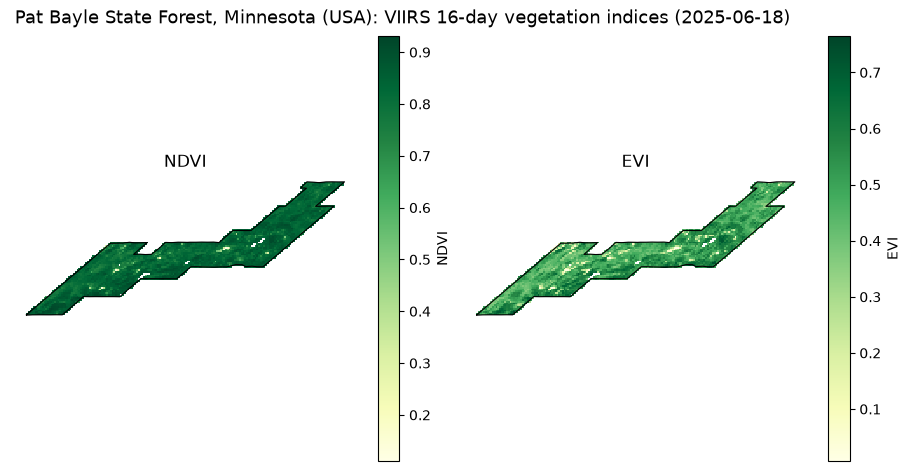

In [24]:
t = "2025-06-18"
date = str(ndvi.sel(time=t, method="nearest").time.values)[:10]  # composite actually plotted

fig, axes = plt.subplots(1, 2, figsize=(9, 4.6), layout="constrained")
fig.suptitle(f"Pat Bayle State Forest, Minnesota (USA): VIIRS 16-day vegetation indices ({date})", x=0.01, ha="left", fontsize=13)

ndvi.sel(time=t, method="nearest").plot.imshow(ax=axes[0], cmap="YlGn", cbar_kwargs={"label": "NDVI"})
evi.sel(time=t, method="nearest").plot.imshow(ax=axes[1], cmap="YlGn", cbar_kwargs={"label": "EVI"})

for ax, name in zip(axes, ["NDVI", "EVI"]):
    aoi.boundary.plot(ax=ax, color="k", lw=0.8)
    ax.set_title(name)
    ax.set_aspect("equal")
    ax.set_axis_off()

plt.show()

## 6. Visualizations of VIIRS Vegetation Data <a id="visualizations"></a>
In this section we calculate the monthly mean NDVI and EVI and plot the results.

### 6.1 Calculate Mean Monthly NDVI/EVI
Here we calculate the mean NDVI and EVI across the forest for each composite date, average those values by year and month, and construct a `pandas` DataFrame with the monthly mean NDVI and EVI values.

In [25]:
def monthly_mean(da):
    return da.mean(["XDim", "YDim"]).resample(time="MS").mean()

ndvi_m = monthly_mean(ndvi)
evi_m = monthly_mean(evi)

monthly = (xr.Dataset({"NDVI": ndvi_m, "EVI": evi_m})
             .to_dataframe()[["NDVI", "EVI"]].dropna())

Now, we can examine the `pandas` DataFrame containing the mean NDVI and EVI for each month.

In [26]:
monthly

,NDVI,EVI
time,,
2024-05-01,0.639858,0.328725
2024-06-01,0.815221,0.471054
2024-07-01,0.786462,0.420419
2024-08-01,0.803337,0.397172
2024-09-01,0.735807,0.317233
2024-10-01,0.635767,0.215525
2025-05-01,0.586144,0.245282
2025-06-01,0.831306,0.492839
2025-07-01,0.783043,0.443290


### 6.2 Create Line Plot
Here, we create an interactive time-series line plot of the monthly mean NDVI and EVI across the quality-filtered pixels of Pat Bayle State Forest for the growing season (May–October). Lines show the trend, dots mark each monthly value, and hovering over the plot shows the exact values.

In [27]:
plot_df = monthly[monthly.index.month.isin(range(5, 11))].copy()
plot_df["month"] = plot_df.index.strftime("%b %Y")
plot_df = plot_df.set_index("month")

COLORS = ["#2a78d6", "#eb6834"]
opts = dict(y=["NDVI", "EVI"], color=COLORS)

line = plot_df.hvplot.line(
    **opts, line_width=2,
    ylabel="Vegetation index", xlabel="", legend="top",
    title="Pat Bayle State Forest, Minnesota (USA) VIIRS VJ113A1 monthly mean NDVI and EVI",
    width=900, height=380, yticks=10, rot=45,
)
dots = plot_df.hvplot.scatter(**opts, size=40)

line * dots

:Overlay
   .NdOverlay.I  :NdOverlay   [Variable]
      :Curve   [month]   (value)
   .NdOverlay.II :NdOverlay   [Variable]
      :Scatter   [month]   (value)

### 6.3 Explore Quality-Filtered NDVI and EVI in an Interactive Map Viewer
This interactive viewer maps the quality-filtered NDVI and EVI for Pat Bayle State Forest on a basemap, with the forest boundary outlined in red. Use the **Layer** menu to switch between NDVI and EVI, and the **Date** slider to step through each 16-day composite from 2024 to 2025.

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
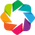

BokehModel(combine_events=True, render_bundle={'docs_json': {'f734ace1-850e-4c38-ae1c-a2254a5ebaf9': {'version…

In [28]:
hv.extension("bokeh")
pn.extension()

# Work around stale Bokeh model errors when the widget re-renders
if not getattr(BokehModel, "_stale_patch", False):
    _sync_model = BokehModel._sync_model
    def _safe_sync_model(self, *args, **kwargs):
        try:
            return _sync_model(self, *args, **kwargs)
        except UnknownReferenceError:
            pass
    BokehModel._sync_model = _safe_sync_model
    BokehModel._stale_patch = True

# --- data: reproject once to lat/lon ---------------------------------------
def to_latlon(da):
    return (da.rio.set_spatial_dims(x_dim="XDim", y_dim="YDim")
              .rio.write_crs(proj)
              .rio.reproject("EPSG:4326", resampling=Resampling.nearest)
              .rename({"x": "lon", "y": "lat"}))

layers = {"NDVI": (to_latlon(ndvi), "YlGn"), "EVI": (to_latlon(evi), "YlGn")}
clims = {k: (float(np.nanmin(da)), float(np.nanmax(da))) for k, (da, _) in layers.items()}
dates = [str(t)[:10] for t in ndvi.time.values]
outline = field.hvplot(geo=True, fill_alpha=0, line_color="red", line_width=3)

# --- widgets ---------------------------------------------------------------
layer_select = pn.widgets.Select(name="Layer", options=list(layers), width=200)
time_slider = pn.widgets.DiscreteSlider(name="Date", options=dates, width=500)

def plot_layer(layer, date):
    da, cmap = layers[layer]
    frame = da.isel(time=dates.index(date)).rename(layer)
    return frame.hvplot.image(
        x="lon", y="lat", geo=True, cmap=cmap, alpha=0.8,
        clim=clims[layer], clabel=layer,
        title=f"Pat Bayle State Forest, Minnesota (USA): VIIRS {layer}, {date}", width=700, height=500)

layer_map = hv.DynamicMap(pn.bind(plot_layer, layer_select, time_slider))

pn.Column(
    pn.Row(layer_select, time_slider),
    pn.pane.HoloViews(gv.tile_sources.EsriWorldLightGrayBase * layer_map * outline),
)

### 6.4 Clean Up Downloaded Data <a id="cleanup"></a>

The VIIRS granules downloaded in Section 3 total about 4.6 GB. We only needed them to read the pixels around Pat Bayle State Forest, and that windowed subset is now held in memory (`ds`, `clipped`, `clipped_nc`, `ndvi` and `evi`). The plots and interactive map above are built from that in-memory data, so the original files are no longer needed.

The next cell deletes the `viirs_data` folder to free disk space. It does not delete `pat_bayle.geojson`, the clipped NetCDF file saved in Section 5.4, or any other file in the `data` directory.

> &#9888;&#65039; **Before you run this cell**
>
> - Cleanup is off by default. Set `CLEANUP = True` to delete the files.
> - Deletion cannot be undone. If you want to rerun Sections 3 and 4 afterward, you will need to download the granules again (about 7.4 GB).
> - The cell closes the open file handles (`tree` and `grid_ds`) first. If Windows still reports a `PermissionError`, restart the kernel and run only this cell.

In [29]:
CLEANUP = False  # set to True to delete the downloaded granules

data_dir = Path("viirs_data")
if CLEANUP and data_dir.exists():
    # release open file handles first (important on Windows)
    for obj in ("tree", "grid_ds"):
        if obj in globals():
            try:
                globals()[obj].close()
            except Exception:
                pass
    size_gb = sum(f.stat().st_size for f in data_dir.rglob("*") if f.is_file()) / 1e9
    shutil.rmtree(data_dir)
    print(f"Deleted {data_dir.resolve()} ({size_gb:.1f} GB)")
else:
    print(f"Left {data_dir.resolve()} in place. Set CLEANUP = True to delete it.")

Left C:\Users\nroberts\MODIS-VIIRS-Data-Resources\data\viirs_data in place. Set CLEANUP = True to delete it.


## 7. Conclusion <a id="conclusion"></a>

In this tutorial, you used `earthaccess` to find and download VIIRS VJ113A1 16-day vegetation indices from the NASA Earthdata Cloud, then built a time series for Pat Bayle State Forest in Minnesota (USA) from the local files.

- **Searched and filtered granules:** You queried CMR with a bounding box, a date range, and the VJ113A1 collection concept ID, then kept the 46 composites that start between May 1 and October 31 of 2024 through 2025.
- **Downloaded the granules:** You saved the filtered granules to a local `viirs_data` folder with `earthaccess.download` and four parallel threads.
- **Matched the read strategy to the file layout:** The VJ113A1 layers are stored as one-row chunks (1 × 2400), with all 16 layers interleaved. Because a small window can't be read without touching neighboring rows and unrelated layers, you read only the pixel window around the forest for the NDVI, EVI, and pixel reliability layers from the local files, loaded it into memory, and combined the granules into a single `xarray` dataset.
- **Post-processed the data:** You georeferenced the dataset on the sinusoidal grid, declared NaN as the nodata value, clipped to the forest boundary, saved the clipped dataset to NetCDF, and read it back to apply a pixel reliability filter that keeps only excellent-quality NDVI and EVI values.
- **Visualized the results:** You calculated monthly mean NDVI and EVI, plotted them as a time series, and explored each quality-filtered composite in an interactive map viewer.
- **Cleaned up:** You optionally deleted the downloaded granules once the data of interest was in memory and saved to NetCDF.

You can now replace the collection concept ID, GeoJSON file, and temporal range in Section 2 with your own inputs and re-run the notebook.

## Contact Info

Email: LPDAAC@usgs.gov  
Voice: +1-866-573-3222  
Organization: Land Processes Distributed Active Archive Center (LP DAAC)¹  
Website: <https://www.earthdata.nasa.gov/centers/lp-daac>  

¹Work performed under USGS contract 140G0126D0001 for NASA contract NNG14HH33I. 